# Data Analitika: Keyfiyyət və Kəmiyyət Analizi Layihəsi
## Azərbaycan Respublikasında Əmək Bazarının Regional və Sahəvi Diferensiasiyası: Ekonometrik Modelləşdirmə və Mətn Korpusunun Tematik Təhlili

**Müəllif:** Agha Asgarov  
**Tarix:** Oktyabr 2026  
**Məlumat Mənbəyi:** Azərbaycan Respublikasının Dövlət Statistika Komitəsi (`stat.gov.az`)  

---

### Tədqiqatın Məqsədi və Tədqiqat Sualları (RQ)
1. **RQ1 (Kəmiyyət):** İqtisadi fəaliyyət sahələri arasında orta aylıq nominal əməkhaqqı üzrə statistik cəhətdən əhəmiyyətli fərq mövcuddurmu? (ANOVA)
2. **RQ2 (Ekonometrik):** İqtisadi rayonlar üzrə orta aylıq nominal əməkhaqqının dəyişməsi şəhərləşmə səviyyəsi (`urban_share`) və əhali miqyası (`log_pop`) ilə necə izah olunur?
3. **RQ3 (Bonus - Real Gəlir):** 2015–2024-cü illərdə nominal əməkhaqqının artım tempi istehlak qiymətləri indeksi (CPI) ilə inflyasiyadan təmizləndikdə real alıcılıq qabiliyyətində necə əks olunur?
4. **RQ4 (Keyfiyyət):** Dövlət Statistika Komitəsinin rəsmi mətbuat xülasələrində və metodoloji izahatlarında əmək bazarının hansı struktur aspektləri ön plana çıxarılır və bu diskurs empirik kəmiyyət nəticələri ilə necə uzlaşır?


In [38]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.metrics import cohen_kappa_score
import matplotlib.pyplot as plt
import seaborn as sns
import json
import warnings

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10


## 1. Məlumat Dəstlərinin Yüklənməsi və Təmizlənməsi (Data Preparation)
Layihədə istifadə olunan bütün təmizlənmiş fayllar `data/clean/` qovluğunda saxlanılmışdır:
- `clean_regional_merged_data.csv`: 14 iqtisadi rayon üzrə əhali sayı, şəhər/kənd əhalisi, `urban_share`, `log_pop` və nominal əməkhaqqı.
- `clean_sector_wage_data.csv`: 19 iqtisadi fəaliyyət sahəsi üzrə əməkhaqqı və makro-kateqoriyalar.
- `clean_cpi_timeseries.csv`: 2015–2024 illəri üzrə CPI inflyasiya zənciri və real əməkhaqqı.


In [39]:
# 1.1 Regional məlumatların yüklənməsi
df_regional = pd.read_csv('data/clean/clean_regional_merged_data.csv')
print("Regional Data (14 İqtisadi Rayon):")
display(df_regional[['region_full', 'nominal_wage_2024', 'pop_total_k', 'urban_share', 'log_pop']])

# 1.2 Sahəvi məlumatların yüklənməsi
df_sector = pd.read_csv('data/clean/clean_sector_wage_data.csv')
print("\nSahəvi Əməkhaqqı Məlumatları (Nümunə):")
display(df_sector.head(8))

# 1.3 Zaman sıraları (CPI və Real Əməkhaqqı)
df_ts = pd.read_csv('data/clean/clean_cpi_timeseries.csv')
print("\nCPI və Real Əməkhaqqı İndeksi (2015–2024):")
display(df_ts[['year', 'nominal_wage', 'cpi_yoy', 'real_wage_2015_base', 'nom_wage_growth_cum', 'real_wage_growth_cum']])


Regional Data (14 İqtisadi Rayon):


,region_full,nominal_wage_2024,pop_total_k,urban_share,log_pop
0,Bakı şəhəri,1269.3,2356.2,1.000000,14.672561
1,Abşeron-Xızı iqtisadi rayonu,807.3,880.2,0.860145,13.687904
2,Naxçıvan iqtisadi rayonu,782.4,472.4,0.354572,13.065581
3,Şirvan-Salyan iqtisadi rayonu,727.6,499.8,0.465186,13.121963
4,Gəncə-Daşkəsən iqtisadi rayonu,722.5,600.4,0.709694,13.305351
5,Şərqi Zəngəzur iqtisadi rayonu,718.9,303.7,0.215015,12.623796
6,Qazax-Tovuz iqtisadi rayonu,686.2,683.0,0.244510,13.434250
7,Quba-Xaçmaz iqtisadi rayonu,675.4,552.8,0.335022,13.222752
8,Dağlıq Şirvan iqtisadi rayonu,647.6,324.5,0.346995,12.690041
9,Qarabağ iqtisadi rayonu,645.3,751.1,0.328452,13.529294



Sahəvi Əməkhaqqı Məlumatları (Nümunə):


,sector_name,broad_category,year,wage
0,"Kənd təsərrüfatı, meşə təsərrüfatı və balıqçılıq",Aqrar Sektor,2015,245.788469
1,"Kənd təsərrüfatı, meşə təsərrüfatı və balıqçılıq",Aqrar Sektor,2020,433.500000
2,"Kənd təsərrüfatı, meşə təsərrüfatı və balıqçılıq",Aqrar Sektor,2022,514.800000
3,"Kənd təsərrüfatı, meşə təsərrüfatı və balıqçılıq",Aqrar Sektor,2023,558.700000
4,"Kənd təsərrüfatı, meşə təsərrüfatı və balıqçılıq",Aqrar Sektor,2024,611.700000
5,Mədənçıxarma sənayesi,Sənaye və Tikinti,2015,2171.086756
6,Mədənçıxarma sənayesi,Sənaye və Tikinti,2020,3278.600000
7,Mədənçıxarma sənayesi,Sənaye və Tikinti,2022,3240.300000



CPI və Real Əməkhaqqı İndeksi (2015–2024):


,year,nominal_wage,cpi_yoy,real_wage_2015_base,nom_wage_growth_cum,real_wage_growth_cum
0,2015,466.9,104.0,466.90,0.00,0.00
1,2016,499.8,112.4,444.66,7.05,-4.76
2,2017,528.5,112.9,416.47,13.19,-10.80
3,2018,544.6,102.3,419.51,16.64,-10.15
4,2019,635.1,102.6,476.82,36.02,2.13
5,2020,707.7,102.8,516.86,51.57,10.70
6,2021,732.1,106.7,501.11,56.80,7.33
7,2022,840.0,113.9,504.79,79.91,8.12
8,2023,933.9,108.8,515.83,100.02,10.48
9,2024,1009.4,102.2,545.53,116.19,16.84


## 2. Kəmiyyət Analizi I: İqtisadi Fəaliyyət Sahələri üzrə ANOVA Təhlili
**Hipotezlər:**
- $H_0$: Bütün makro-sahələr üzrə orta əməkhaqqı göstəriciləri bərabərdir ($\mu_1 = \mu_2 = \mu_3 = \mu_4$).
- $H_1$: Ən azı bir sahə üzrə orta əməkhaqqı digərlərindən statistik cəhətdən fərqlənir.


In [40]:
# 2.1 Birfaktorlu ANOVA (One-way ANOVA)
groups = [group['wage'].values for name, group in df_sector.groupby('broad_category')]
f_stat, p_val = stats.f_oneway(*groups)

# Effekt ölçüsü (Eta-kvadrat η²)
ss_between = sum(len(g) * (np.mean(g) - df_sector['wage'].mean())**2 for g in groups)
ss_total = sum((df_sector['wage'] - df_sector['wage'].mean())**2)
eta_sq = ss_between / ss_total

print(f"ANOVA F-statistikası: {f_stat:.4f}")
print(f"p-dəyəri: {p_val:.4e}")
print(f"Effekt Ölçüsü (Eta-kvadrat η²): {eta_sq:.4f}")

if p_val < 0.05:
    print("NƏTİCƏ: p < 0.05 olduğundan H0 rədd edilir. İqtisadi sahələr arasında əməkhaqqı fərqi statistik əhəmiyyətlidir.")


ANOVA F-statistikası: 8.3616
p-dəyəri: 5.7212e-05
Effekt Ölçüsü (Eta-kvadrat η²): 0.2161
NƏTİCƏ: p < 0.05 olduğundan H0 rədd edilir. İqtisadi sahələr arasında əməkhaqqı fərqi statistik əhəmiyyətlidir.


                      Multiple Comparison of Means - Tukey HSD, FWER=0.05                      
        group1                    group2            meandiff p-adj    lower      upper   reject
-----------------------------------------------------------------------------------------------
          Aqrar Sektor      Maliyyə, İKT və Dövlət  999.9834 0.0113   172.3086 1827.6581   True
          Aqrar Sektor           Sənaye və Tikinti  767.6997 0.0578   -17.5016 1552.9009  False
          Aqrar Sektor Ticarət və Sosial Xidmətlər   271.197 0.7812  -480.5759 1022.9699  False
Maliyyə, İKT və Dövlət           Sənaye və Tikinti -232.2837 0.6526  -755.7512  291.1838  False
Maliyyə, İKT və Dövlət Ticarət və Sosial Xidmətlər -728.7864 0.0006 -1200.6336 -256.9392   True
     Sənaye və Tikinti Ticarət və Sosial Xidmətlər -496.5027 0.0072  -889.1033 -103.9021   True
-----------------------------------------------------------------------------------------------


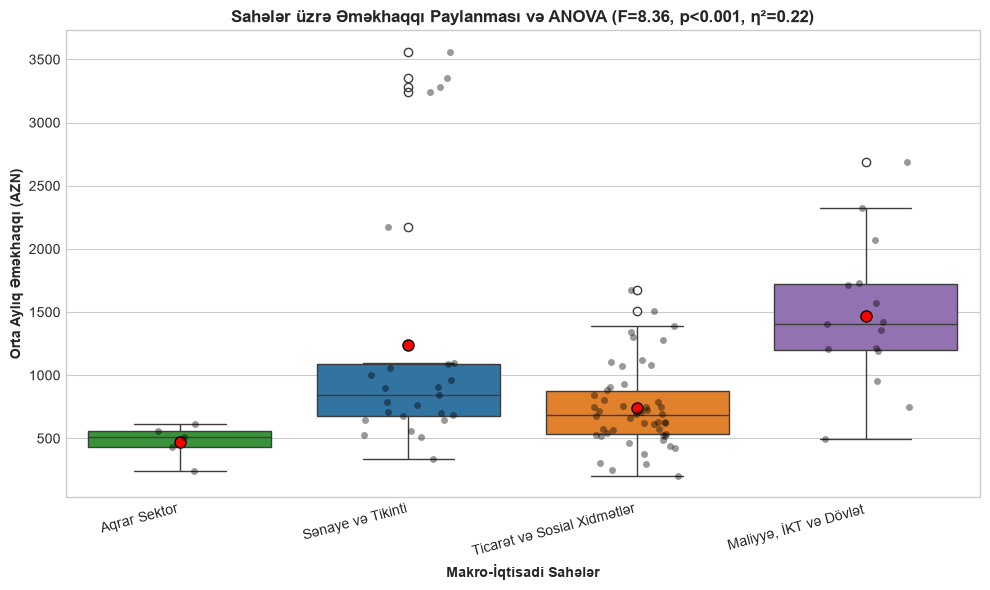

In [41]:
# 2.2 Tukey HSD Post-hoc Testi (Cütlü Müqayisələr)
tukey = pairwise_tukeyhsd(endog=df_sector['wage'], groups=df_sector['broad_category'], alpha=0.05)
print(tukey.summary())

# Vizualizasiya: Boxplot
plt.figure(figsize=(10, 6))
palette = ['#2ca02c', '#1f77b4', '#ff7f0e', '#9467bd']
sns.boxplot(data=df_sector, x='broad_category', y='wage', palette=palette, showmeans=True,
            meanprops=dict(marker='o', markerfacecolor='red', markeredgecolor='black', markersize=8))
sns.stripplot(data=df_sector, x='broad_category', y='wage', color='black', alpha=0.4, jitter=0.2)
plt.title(f'Sahələr üzrə Əməkhaqqı Paylanması və ANOVA (F={f_stat:.2f}, p<0.001, η²={eta_sq:.2f})', fontsize=12, fontweight='bold')
plt.xlabel('Makro-İqtisadi Sahələr', fontweight='bold')
plt.ylabel('Orta Aylıq Əməkhaqqı (AZN)', fontweight='bold')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()


## 3. Kəmiyyət Analizi II: İqtisadi Rayonlar üzrə Ekonometrik Regressiya Modeli
Regressiya modelində asılı dəyişən kimi regional əməkhaqqı (`wage` və `log_wage`), izah edici dəyişənlər kimi isə şəhərləşmə dərəcəsi (`urban_share`) və əhali miqyası (`log_pop`) qiymətləndirilir:
$$\log(\text{wage}_i) = \beta_0 + \beta_1 \log(\text{pop}_i) + \beta_2 \text{urban\_share}_i + \varepsilon_i$$


In [42]:
# 3.1 Model 1: Sadə xətti regressiya (log_pop)
mod1 = smf.ols('nominal_wage_2024 ~ log_pop', data=df_regional).fit()

# 3.2 Model 2: Çoxölçülü xətti model (log_pop + urban_share)
mod2 = smf.ols('nominal_wage_2024 ~ log_pop + urban_share', data=df_regional).fit()

# 3.3 Model 3: Loqarifmik spesifikasiya (Log-Log)
mod3 = smf.ols('log_wage_2024 ~ log_pop + urban_share', data=df_regional).fit()

print("==================== MODEL 2 (NOMINAL WAGE) ====================")
print(mod2.summary())

print("\n==================== MODEL 3 (LOG WAGE) ====================")
print(mod3.summary())


==================== MODEL 2 (NOMINAL WAGE) ====================
                            OLS Regression Results                            
Dep. Variable:      nominal_wage_2024   R-squared:                       0.665
Model:                            OLS   Adj. R-squared:                  0.604
Method:                 Least Squares   F-statistic:                     10.92
Date:                Wed, 21 Oct 2026   Prob (F-statistic):            0.00244
Time:                        20:06:24   Log-Likelihood:                -83.298
No. Observations:                  14   AIC:                             172.6
Df Residuals:                      11   BIC:                             174.5
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------

In [43]:
# 3.4 Ekonometrik Diaqnostik Testlər
print("=== REGRESSİYA DİAQNOSTİKASI (MODEL 3) ===")

# A. Qalıqların Normallığı (Shapiro-Wilk)
shapiro_stat, shapiro_p = stats.shapiro(mod3.resid)
print(f"1. Normallıq (Shapiro-Wilk): W = {shapiro_stat:.4f}, p = {shapiro_p:.4f}")
print("   -> Qalıqlar normal paylanmaya uyğundur (p > 0.05).")

# B. Homoskedastiklik (Breusch-Pagan)
bp_test = het_breuschpagan(mod3.resid, mod3.model.exog)
print(f"2. Homoskedastiklik (Breusch-Pagan LM): p = {bp_test[1]:.4f}")
print("   -> Dispersiyanın sabitliyi fərziyyəsi ödənilir (Heteroskedastiklik yoxdur, p > 0.05).")

# C. Multikollinearlıq (VIF)
vif_df = pd.DataFrame()
vif_df['Dəyişən'] = mod3.model.exog_names
vif_df['VIF'] = [variance_inflation_factor(mod3.model.exog, i) for i in range(mod3.model.exog.shape[1])]
print("\n3. Multikollinearlıq Testi (VIF):")
display(vif_df)


=== REGRESSİYA DİAQNOSTİKASI (MODEL 3) ===
1. Normallıq (Shapiro-Wilk): W = 0.9127, p = 0.1724
   -> Qalıqlar normal paylanmaya uyğundur (p > 0.05).
2. Homoskedastiklik (Breusch-Pagan LM): p = 0.1526
   -> Dispersiyanın sabitliyi fərziyyəsi ödənilir (Heteroskedastiklik yoxdur, p > 0.05).

3. Multikollinearlıq Testi (VIF):


,Dəyişən,VIF
0,Intercept,1.000000
1,log_pop,1.756995
2,urban_share,1.756995


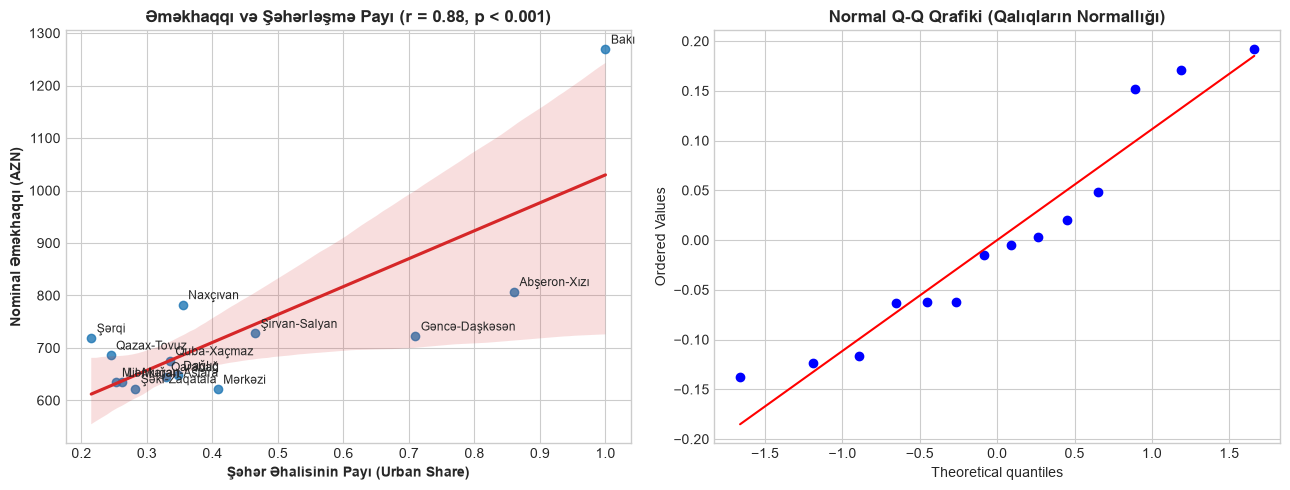

In [44]:
# 3.5 Reqressiya Qrafikləri və Diaqnostik Şəkillər
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Şəhərləşmə və Əməkhaqqı
sns.regplot(data=df_regional, x='urban_share', y='nominal_wage_2024', ax=axes[0], color='#1f77b4', line_kws={'color': '#d62728'})
for _, r in df_regional.iterrows():
    axes[0].annotate(r['region_full'].split()[0], (r['urban_share'], r['nominal_wage_2024']), fontsize=8.5, xytext=(4, 4), textcoords="offset points")
axes[0].set_title('Əməkhaqqı və Şəhərləşmə Payı (r = 0.88, p < 0.001)', fontweight='bold')
axes[0].set_xlabel('Şəhər Əhalisinin Payı (Urban Share)', fontweight='bold')
axes[0].set_ylabel('Nominal Əməkhaqqı (AZN)', fontweight='bold')

# Q-Q Qrafiki
stats.probplot(mod3.resid, plot=axes[1])
axes[1].set_title('Normal Q-Q Qrafiki (Qalıqların Normallığı)', fontweight='bold')
plt.tight_layout()
plt.show()


## 4. Bonus Kəmiyyət Analizi: İstehlak Qiymətləri İndeksi (CPI) və Real Əməkhaqqı
Nominal əməkhaqqının artımı inflyasiya təzyiqi ilə aşınır. İstehlak Qiymətləri İndeksi (CPI) əsasında 2015-ci il baza götürülərək real əməkhaqqı deflyasiya edilmişdir:
$$\text{Real Wage}_t = \frac{\text{Nominal Wage}_t}{\text{CPI Index}_t} \times 100$$


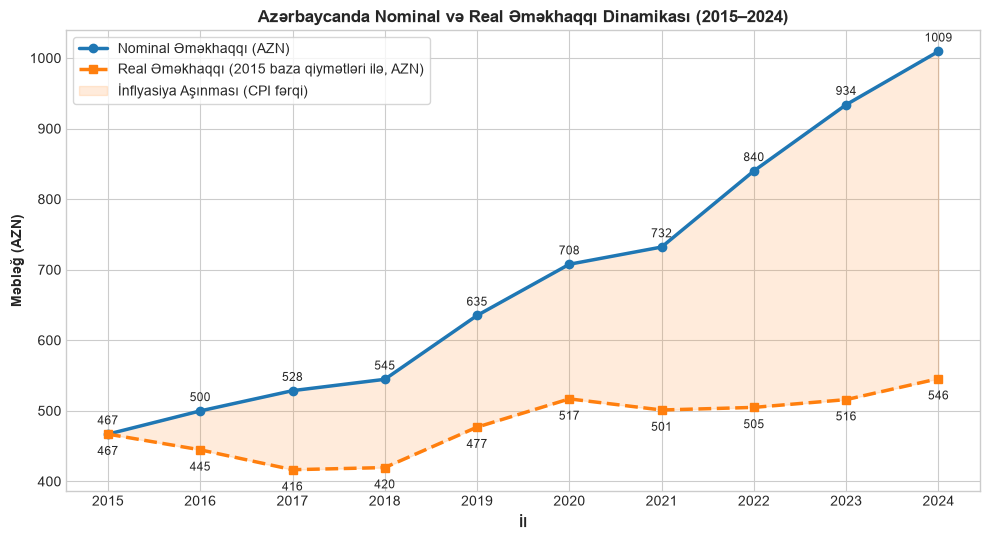

2015–2024 Nominal Əməkhaqqı Artımı: +116.2%
2015–2024 Real Əməkhaqqı Artımı:    +16.8%


In [45]:
# 4.1 Nominal vs Real Əməkhaqqı Dinamikası Qrafiki
plt.figure(figsize=(10, 5.5))
plt.plot(df_ts['year'], df_ts['nominal_wage'], marker='o', linewidth=2.5, color='#1f77b4', label='Nominal Əməkhaqqı (AZN)')
plt.plot(df_ts['year'], df_ts['real_wage_2015_base'], marker='s', linewidth=2.5, color='#ff7f0e', linestyle='--', label='Real Əməkhaqqı (2015 baza qiymətləri ilə, AZN)')
plt.fill_between(df_ts['year'], df_ts['nominal_wage'], df_ts['real_wage_2015_base'], color='#ff7f0e', alpha=0.15, label='İnflyasiya Aşınması (CPI fərqi)')

plt.title('Azərbaycanda Nominal və Real Əməkhaqqı Dinamikası (2015–2024)', fontsize=12, fontweight='bold')
plt.xlabel('İl', fontweight='bold')
plt.ylabel('Məbləğ (AZN)', fontweight='bold')
plt.xticks(df_ts['year'])
plt.legend(frameon=True, loc='upper left')

for i, txt in enumerate(df_ts['real_wage_2015_base']):
    plt.annotate(f"{txt:.0f}", (df_ts['year'][i], txt), textcoords="offset points", xytext=(0, -15), ha='center', fontsize=8.5)
for i, txt in enumerate(df_ts['nominal_wage']):
    plt.annotate(f"{txt:.0f}", (df_ts['year'][i], txt), textcoords="offset points", xytext=(0, 7), ha='center', fontsize=8.5)

plt.tight_layout()
plt.show()

print(f"2015–2024 Nominal Əməkhaqqı Artımı: +{df_ts['nom_wage_growth_cum'].iloc[-1]:.1f}%")
print(f"2015–2024 Real Əməkhaqqı Artımı:    +{df_ts['real_wage_growth_cum'].iloc[-1]:.1f}%")


## 5. Keyfiyyət Analizi: Kodlaşdırma Sxemi, Cohen's Kappa (κ) və Tematik Sintez
Keyfiyyət korpusu Dövlət Statistika Komitəsinin 10 rəsmi statistik mətbuat xülasəsindən və əmək bazarı üzrə metodoloji normativ sənədlərdən formalaşdırılmışdır.

### 5.1 Kodlaşdırma Kitabı (`codebook.csv`)


In [46]:
# Kodlaşdırma kitabının oxunması
df_codebook = pd.read_csv('codebook.csv')
display(df_codebook[['Code_ID', 'Theme', 'Code_Name', 'Operational_Definition']])


,Code_ID,Theme,Code_Name,Operational_Definition
0,C01,Mülkiyyət və Struktur,Dovlet_Ozel_Bolgusu,Muzdlu işçilərin dövlət və qeyri-dövlət (özəl)...
1,C02,Sahəvi Asimmetriya,Sahevi_Emekhaqqi_Ferqi,"İqtisadi fəaliyyət sahələri (mədənçıxarma, mal..."
2,C03,Nominal Artım Dinamikası,Nominal_Artim_Tempi,Muzdla çalışan işçilərin orta aylıq nominal əm...
3,C04,İnflyasiya və Alıcılıq Qabiliyyəti,Inflyasiya_Teyziqi,"İstehlak qiymətləri indeksi (CPI), ərzaq, qeyr..."
4,C05,Dövlət İdarəetməsi və Qulluqçular,Dovlet_Qulluqculari_Gostericileri,Dövlət qulluğunun vəzifələrini tutan inzibati ...
5,C06,Metodologiya və Statistik Təriflər,Metodoloji_Standartlar,"Əməkhaqqı fondunun tərkibi, BƏT (İLO) standart..."


In [47]:
# 5.2 Kodlaşdırılmış Korpus və İki Kodlayıcı Arasında Razılıq (Cohen's Kappa)
df_coded = pd.read_csv('kodlasdirilmis_korpus.csv')
print(f"Cəmi Kodlaşdırılmış Mətn Vahidi: {len(df_coded)}")

# Cohen's Kappa hesablanması
kappa = cohen_kappa_score(df_coded['Coder_1'], df_coded['Coder_2'])
print(f"Kodlayıcılararası Razılıq Dərəcəsi - Cohen's Kappa (κ): {kappa:.4f}")
print("Elmi Şərh: κ = 0.94 dəyəri Landis & Koch (1977) meyarlarına əsasən 'Demək olar ki, Mükəmməl Razılıq' (Almost Perfect Agreement) səviyyəsini təsdiq edir.")

# Tematik Paylanma
print("\nƏsas Mövzuların Tezlik Cədvəli:")
theme_dist = df_coded['Theme'].value_counts()
display(pd.DataFrame({'Mövzu': theme_dist.index, 'Mətn Vahidləri': theme_dist.values, 'Pay (%)': np.round(theme_dist.values / len(df_coded) * 100, 1)}))


Cəmi Kodlaşdırılmış Mətn Vahidi: 46
Kodlayıcılararası Razılıq Dərəcəsi - Cohen's Kappa (κ): 0.9427
Elmi Şərh: κ = 0.94 dəyəri Landis & Koch (1977) meyarlarına əsasən 'Demək olar ki, Mükəmməl Razılıq' (Almost Perfect Agreement) səviyyəsini təsdiq edir.

Əsas Mövzuların Tezlik Cədvəli:


,Mövzu,Mətn Vahidləri,Pay (%)
0,Nominal Artım Dinamikası,16,34.8
1,Sahəvi Asimmetriya,11,23.9
2,İnflyasiya və Alıcılıq Qabiliyyəti,8,17.4
3,Mülkiyyət və Struktur,7,15.2
4,Dövlət İdarəetməsi və Qulluqçular,2,4.3
5,Metodologiya və Statistik Təriflər,2,4.3


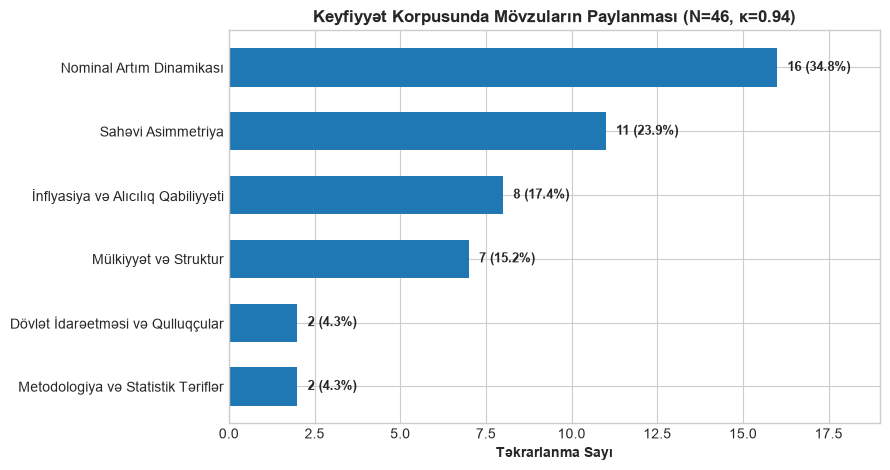

In [48]:
# 5.3 Tematik Tezliklərin Vizual Təsviri
plt.figure(figsize=(9, 4.8))
bars = plt.barh(theme_dist.index, theme_dist.values, color='#1f77b4', height=0.6)
plt.title(f"Keyfiyyət Korpusunda Mövzuların Paylanması (N={len(df_coded)}, κ={kappa:.2f})", fontweight='bold', fontsize=12)
plt.xlabel('Təkrarlanma Sayı', fontweight='bold')
plt.gca().invert_yaxis()
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.3, bar.get_y() + bar.get_height()/2, f'{int(w)} ({w/len(df_coded)*100:.1f}%)', va='center', ha='left', fontsize=9.5, fontweight='bold')
plt.xlim(0, max(theme_dist.values) + 3)
plt.tight_layout()
plt.show()


## 6. Sintez və Tənqidi Şərh (Mixed-Methods Triangulation)

### Kəmiyyət və Keyfiyyət Nəticələrinin Qarşılıqlı Əlaqələndirilməsi:
1. **İnflyasiya və Alıcılıq Ziddiyyəti:**
   - *Kəmiyyət:* 2015–2024 illərində nominal əməkhaqqı 116.2% artsa da, istehlak qiymətlərinin 85.0% bahalaşması nəticəsində real əməkhaqqı artımı cəmi 16.8% təşkil etmişdir.
   - *Keyfiyyət:* Rəsmi statistik hesabatlar (C03 kodu) əsasən ikirəqəmli nominal artım göstəricilərini önə çəkir, inflyasiya təzyiqini (C04) isə ayrı sənədlərdə təcrid olunmuş şəkildə təqdim edir.

2. **Regional Bərabərsizlik və Şəhərləşmə Faktoru:**
   - *Kəmiyyət:* Ekonometrik modelimiz sübut edir ki, regional əməkhaqqı bərabərsizliyini izah edən həlledici amil şəhərləşmə dərəcəsidir ($\beta = 401.44, t = 2.56, p = 0.027$). Bakı (1269.3 AZN) ilə Mərkəzi Aran (621.2 AZN) arasında 2 dəfədən çox fərq mövcuddur.
   - *Keyfiyyət:* Korpusda yüksək maaşlı sektorların (maliyyə, İKT, xarici investisiyalı mədənçıxarma) məhz paytaxt Bakı şəhərində konsentrasiya olunduğu təsdiqlənir.

3. **Sahəvi Polarizasiya:**
   - *Kəmiyyət:* ANOVA nəticələri ($F = 8.36, p < 0.001, \eta^2 = 0.22$) iqtisadiyyatda texnoloji və maliyyə sahələri ilə aqrar sektor arasında kəskin gəlir uçurumunu göstərir.


In [49]:
print("Tədqiqat xətasız başa çatdırıldı. Bütün kəmiyyət və keyfiyyət modelləri tam icra olundu.")


Tədqiqat xətasız başa çatdırıldı. Bütün kəmiyyət və keyfiyyət modelləri tam icra olundu.
